<a href="https://colab.research.google.com/github/mokshitakapoor0129/Celebal_Training_Programming_Questions/blob/main/HDFC_Loan_ML_Foundations_Statsmodels_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HDFC Loan Dataset: ML Foundations, Statistics, Preprocessing & Statsmodels
**Google Colab practical notebook**

## Learning sequence
1. Machine Learning foundations
2. Statistics and linear algebra
3. Exploratory data analysis (EDA)
4. Data cleaning and preprocessing
5. Statistical analysis with Statsmodels (before model selection)
6. Model selection considerations

**Dataset:** [Link](https://drive.google.com/file/d/1HUnoJajgfvjwaSmIOeG9GdkC2orn6w3E/view?usp=sharing)

> In Colab, upload the CSV using the upload cell below, or mount Google Drive and update the path. Results depend on the uploaded file version. Treat the dataset as a learning dataset, not as evidence about real lending outcomes.

## 1. Import libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload the CSV to Google Colab
Run this cell and choose the uploaded HDFC CSV from your computer. If it is already in Google Drive, skip this cell and set `CSV_PATH` in the next cell.

In [14]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# List contents of Drive to confirm access
print("Google Drive mounted successfully. Checking Drive contents...")
print(os.listdir('/content/drive/My Drive')[:5])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully. Checking Drive contents...
['ads assessment', 'Saved from the Google app', 'Practice 1m MCQs.gsheet', 'Classroom', 'Colab Notebooks']


In [24]:
# Automatically select the uploaded CSV.
# If you use Google Drive instead, replace this with its full path.

df = pd.read_csv('/content/hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv')
print("Loaded file:", df)
print("Dataset shape:", df.shape)
display(df.head())

Loaded file:         Loan_ID       Bank   Customer_Name  Gender Married  Dependents  \
0    HDFC100001  HDFC Bank     Rohan Verma    Male      No           2   
1    HDFC100002  HDFC Bank     Rohan Verma    Male      No           0   
2    HDFC100003  HDFC Bank     Aditya Nair  Female     Yes           0   
3    HDFC100004  HDFC Bank    Ananya Joshi    Male      No           0   
4    HDFC100005  HDFC Bank  Harpreet Singh    Male     Yes           3   
..          ...        ...             ...     ...     ...         ...   
995  HDFC100996  HDFC Bank     Simran Kaur    Male     Yes           1   
996  HDFC100997  HDFC Bank   Krishna Mehta    Male      No           2   
997  HDFC100998  HDFC Bank     Rohan Verma  Female      No           1   
998  HDFC100999  HDFC Bank    Ananya Joshi  Female      No           2   
999  HDFC101000  HDFC Bank    Saanvi Reddy  Female     Yes           0   

    Education Employment_Status  Applicant_Income  Coapplicant_Income  ...  \
0    Graduate       

,Loan_ID,Bank,Customer_Name,Gender,Married,Dependents,Education,Employment_Status,Applicant_Income,Coapplicant_Income,...,Loan_to_Annual_Income,Customer_Sentiment,Religion,State,City,PIN_Code,Aadhaar_Synthetic,Phone_Number,Email,Occupation
0,HDFC100001,HDFC Bank,Rohan Verma,Male,No,2,Graduate,Salaried,56976,0,...,11.747,Positive,Hindu,Delhi,Dwarka,857743,6.940000e+11,9068671773,rohan.verma@example.in,Farmer
1,HDFC100002,HDFC Bank,Rohan Verma,Male,No,0,Graduate,Unemployed,1856,0,...,40.381,Negative,Hindu,Punjab,Ludhiana,863836,6.330000e+11,9990772625,rohan.verma@example.in,Civil Engineer
2,HDFC100003,HDFC Bank,Aditya Nair,Female,Yes,0,Graduate,Salaried,64553,0,...,3.082,Positive,Hindu,Maharashtra,Nagpur,834796,1.660000e+11,9195085016,aditya.nair@example.in,Medical Representative
3,HDFC100004,HDFC Bank,Ananya Joshi,Male,No,0,Graduate,Salaried,88450,0,...,0.621,Negative,Hindu,Gujarat,Vadodara,438590,5.528183e+10,9179335548,ananya.joshi@example.in,Marketing Executive
4,HDFC100005,HDFC Bank,Harpreet Singh,Male,Yes,3,Graduate,Self-Employed,9539,0,...,1.736,Neutral,Sikh,West Bengal,Kolkata,495224,1.560000e+11,9795137116,harpreet.singh@example.in,Shopkeeper


In [16]:
import pandas as pd
import os

files = os.listdir('/content')
print(files)

['.config', 'hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv', 'drive', 'sample_data']


In [17]:
import pandas as pd

df = pd.read_csv(
    '/content/hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv'
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1000, 47)


,Loan_ID,Bank,Customer_Name,Gender,Married,Dependents,Education,Employment_Status,Applicant_Income,Coapplicant_Income,...,Loan_to_Annual_Income,Customer_Sentiment,Religion,State,City,PIN_Code,Aadhaar_Synthetic,Phone_Number,Email,Occupation
0,HDFC100001,HDFC Bank,Rohan Verma,Male,No,2,Graduate,Salaried,56976,0,...,11.747,Positive,Hindu,Delhi,Dwarka,857743,6.940000e+11,9068671773,rohan.verma@example.in,Farmer
1,HDFC100002,HDFC Bank,Rohan Verma,Male,No,0,Graduate,Unemployed,1856,0,...,40.381,Negative,Hindu,Punjab,Ludhiana,863836,6.330000e+11,9990772625,rohan.verma@example.in,Civil Engineer
2,HDFC100003,HDFC Bank,Aditya Nair,Female,Yes,0,Graduate,Salaried,64553,0,...,3.082,Positive,Hindu,Maharashtra,Nagpur,834796,1.660000e+11,9195085016,aditya.nair@example.in,Medical Representative
3,HDFC100004,HDFC Bank,Ananya Joshi,Male,No,0,Graduate,Salaried,88450,0,...,0.621,Negative,Hindu,Gujarat,Vadodara,438590,5.528183e+10,9179335548,ananya.joshi@example.in,Marketing Executive
4,HDFC100005,HDFC Bank,Harpreet Singh,Male,Yes,3,Graduate,Self-Employed,9539,0,...,1.736,Neutral,Sikh,West Bengal,Kolkata,495224,1.560000e+11,9795137116,harpreet.singh@example.in,Shopkeeper


## 3. Machine Learning foundations
- **AI:** broad field of systems performing tasks associated with human intelligence.
- **ML:** subset of AI that learns patterns from data.
- **Supervised learning:** learns from labeled examples; examples include regression and classification.
- **Unsupervised learning:** finds structure without a target label; examples include clustering and dimensionality reduction.
- **Regression:** predicts a continuous value, e.g. loan amount.
- **Classification:** predicts a class, e.g. approved/rejected.

**ML lifecycle:** business problem → data understanding → preprocessing → feature engineering → train/validation/test → evaluation → deployment and monitoring.

## 4. Dataset structure and data types

In [19]:
print("Rows, columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDescriptive summary:")
display(df.describe(include="all").T)

Rows, columns: (1000, 47)

Column names:
['Loan_ID', 'Bank', 'Customer_Name', 'Gender', 'Married', 'Dependents', 'Education', 'Employment_Status', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Term_Months', 'Credit_History', 'Property_Area', 'Age', 'Loan_Status', 'CIBIL_Score', 'Annual_Household_Income', 'Debt_to_Income_Ratio', 'Purpose_of_Loan', 'Existing_EMIs', 'Number_of_Previous_Loans', 'Default_History_Count', 'Employment_Length_Years', 'Business_Type', 'Asset_Value', 'Guarantor', 'Co-signer_Relationship', 'Monthly_Expense', 'Organization_Type', 'Region_Branch', 'Mobile_Verified', 'Email_Verified', 'Institutional_Relationships', 'Application_Text', 'Customer_Feedback', 'Agent_Notes', 'Loan_to_Annual_Income', 'Customer_Sentiment', 'Religion', 'State', 'City', 'PIN_Code', 'Aadhaar_Synthetic', 'Phone_Number', 'Email', 'Occupation']

Data types:


,dtype
Loan_ID,object
Bank,object
Customer_Name,object
Gender,object
Married,object
Dependents,int64
Education,object
Employment_Status,object
Applicant_Income,int64
Coapplicant_Income,int64



Descriptive summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,1000,1000,HDFC101000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bank,1000,1,HDFC Bank,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,1000,41,Ananya Joshi,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1000,3,Male,651,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,1000,2,Yes,592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,1000.0,NaN,NaN,NaN,0.849,0.964951,0.0,0.0,1.0,2.0,3.0
Education,1000,2,Graduate,717,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment_Status,1000,4,Salaried,591,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Applicant_Income,1000.0,NaN,NaN,NaN,42430.057,28133.210769,0.0,18260.0,40675.5,61037.25,149266.0
Coapplicant_Income,1000.0,NaN,NaN,NaN,9727.114,20568.25945,0.0,0.0,0.0,7956.5,123461.0


## 5. Statistics: descriptive analysis

In [21]:
# Use only columns that exist in this dataset.
financial_candidates = [
    "Applicant_Income", "Coapplicant_Income", "Loan_Amount",
    "Age", "CIBIL_Score", "Annual_Household_Income",
    "Debt_to_Income_Ratio", "Existing_EMIs"
]
financial_cols = [c for c in financial_candidates if c in df.columns]

display(df[financial_cols].describe().T)

for col in financial_cols:
    print(f"{col}: mean={df[col].mean():.3f}, median={df[col].median():.3f}, std={df[col].std():.3f}")

,count,mean,std,min,25%,50%,75%,max
Applicant_Income,1000.0,4.243006e+04,2.813321e+04,0.0,18260.000,40675.500,61037.250,149266.0
Coapplicant_Income,1000.0,9.727114e+03,2.056826e+04,0.0,0.000,0.000,7956.500,123461.0
Loan_Amount,1000.0,2.216713e+06,2.635021e+06,1884.0,372946.500,972046.000,3315037.750,13790960.0
Age,1000.0,3.441200e+01,8.572616e+00,18.0,28.000,35.000,40.000,66.0
CIBIL_Score,1000.0,6.530130e+02,7.383654e+01,384.0,605.750,654.000,704.000,878.0
Annual_Household_Income,1000.0,6.258861e+05,4.724545e+05,0.0,263952.000,551244.000,856548.000,2555340.0
Debt_to_Income_Ratio,1000.0,1.481182e+02,1.974599e+03,0.0,0.031,0.332,0.795,38342.0
Existing_EMIs,1000.0,1.817339e+04,1.629846e+04,0.0,1741.750,16289.500,29718.500,82436.0


Applicant_Income: mean=42430.057, median=40675.500, std=28133.211
Coapplicant_Income: mean=9727.114, median=0.000, std=20568.259
Loan_Amount: mean=2216712.901, median=972046.000, std=2635020.932
Age: mean=34.412, median=35.000, std=8.573
CIBIL_Score: mean=653.013, median=654.000, std=73.837
Annual_Household_Income: mean=625886.052, median=551244.000, std=472454.503
Debt_to_Income_Ratio: mean=148.118, median=0.332, std=1974.599
Existing_EMIs: mean=18173.390, median=16289.500, std=16298.461


## 6. Probability and target distribution

Counts:


,count
Loan_Status,
Approved,653
Rejected,347


Percentages:


,proportion
Loan_Status,
Approved,65.3
Rejected,34.7


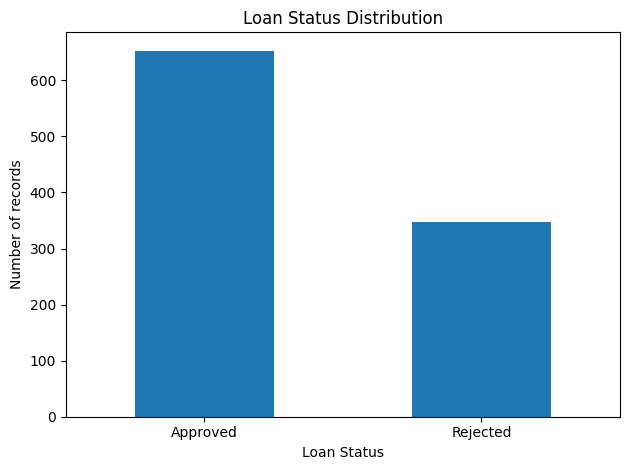

In [22]:
if "Loan_Status" in df.columns:
    print("Counts:")
    display(df["Loan_Status"].value_counts(dropna=False))
    print("Percentages:")
    display((df["Loan_Status"].value_counts(normalize=True, dropna=False) * 100).round(2))

    df["Loan_Status"].value_counts(dropna=False).plot(kind="bar")
    plt.title("Loan Status Distribution")
    plt.xlabel("Loan Status")
    plt.ylabel("Number of records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Loan_Status not found. Inspect the column list and select the appropriate target.")

## 7. Visualize distributions and correlation

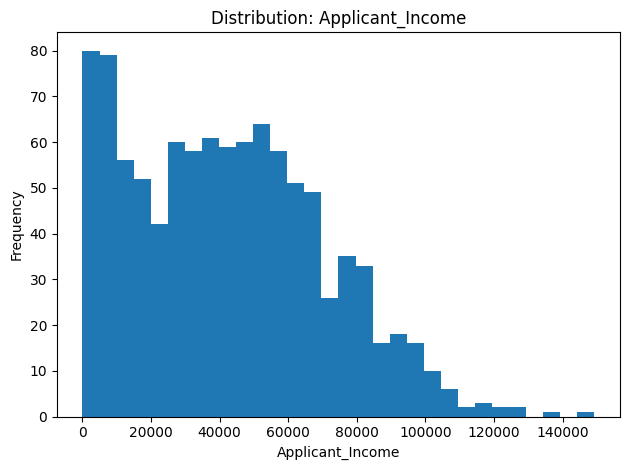

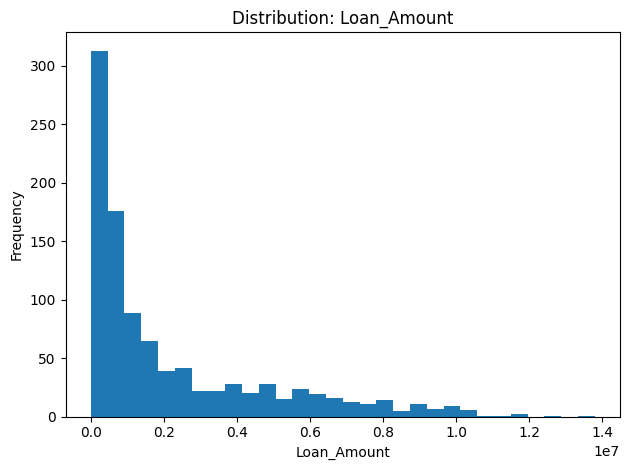

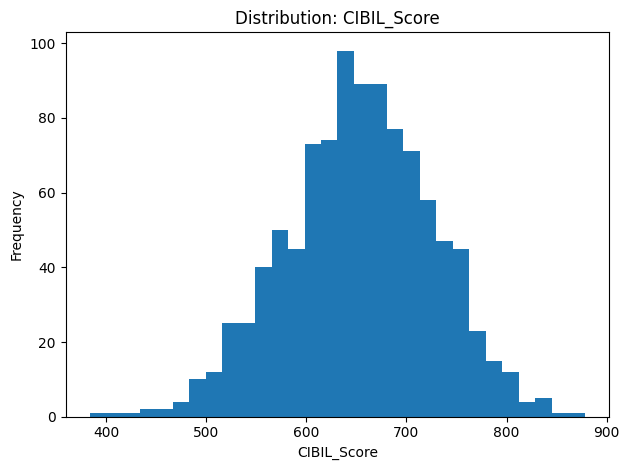

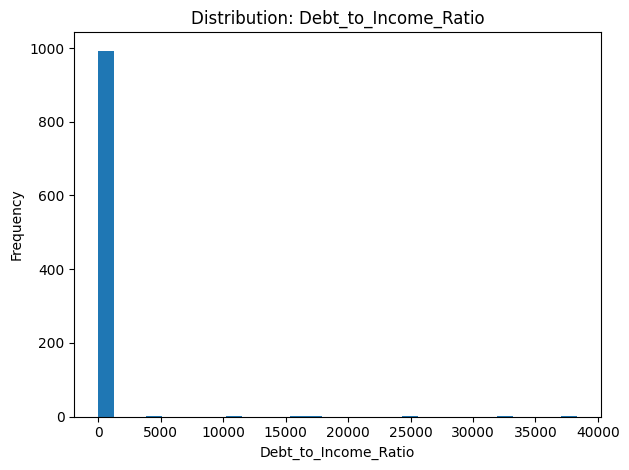

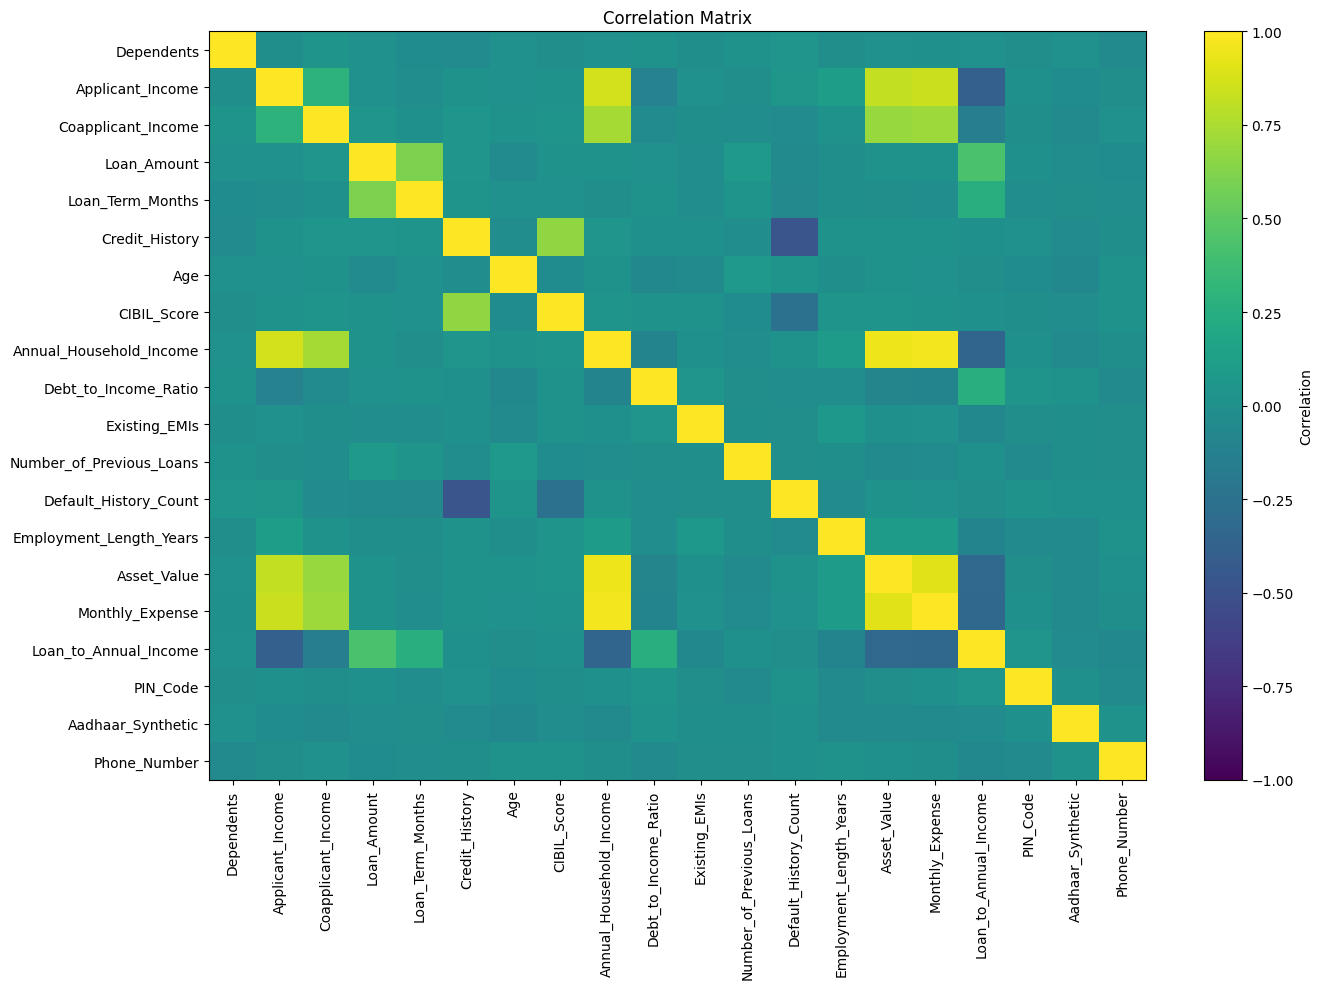

In [23]:
for col in [c for c in ["Applicant_Income", "Loan_Amount", "CIBIL_Score", "Debt_to_Income_Ratio"] if c in df.columns]:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    plt.figure()
    plt.hist(values, bins=30)
    plt.title(f"Distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if len(numeric_cols) >= 2:
    corr = df[numeric_cols].corr()
    plt.figure(figsize=(min(14, 0.8 * len(numeric_cols) + 4), min(10, 0.7 * len(numeric_cols) + 3)))
    plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90)
    plt.yticks(range(len(numeric_cols)), numeric_cols)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

## 8. Linear algebra with NumPy
A row of a numeric feature matrix represents one applicant; columns represent features. Matrix multiplication forms weighted sums used by many models.

In [ ]:
example_cols = [c for c in ["Applicant_Income", "Coapplicant_Income", "CIBIL_Score"] if c in df.columns]
if len(example_cols) == 3:
    X_demo = df[example_cols].apply(pd.to_numeric, errors="coerce").dropna().head(5).to_numpy()
    print("Selected features:", example_cols)
    print("Matrix:\n", X_demo)
    print("Shape:", X_demo.shape)
    print("Column means:", X_demo.mean(axis=0))

    weights = np.array([0.00001, 0.00001, 0.01])  # Arbitrary demonstration weights, not a trained model
    print("Weighted scores:", X_demo @ weights)
else:
    print("Required numeric columns not found. Select three numeric columns from the dataset.")

## 9. Data quality: missing values and duplicates

In [ ]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_report[missing_report["Missing_Count"] > 0])
print("Fully duplicated rows:", df.duplicated().sum())

if "Loan_ID" in df.columns:
    print("Duplicate Loan_ID values:", df["Loan_ID"].duplicated().sum())
    display(df[df["Loan_ID"].duplicated(keep=False)].head(10))

## 10. Domain checks and outlier investigation
These are example rules. Confirm valid ranges from the data dictionary before changing or removing records.

In [ ]:
checks = {}
if "Applicant_Income" in df.columns:
    checks["Negative applicant income"] = pd.to_numeric(df["Applicant_Income"], errors="coerce") < 0
if "Loan_Amount" in df.columns:
    checks["Negative loan amount"] = pd.to_numeric(df["Loan_Amount"], errors="coerce") < 0
if "Age" in df.columns:
    checks["Age outside illustrative 18–100 range"] = ~pd.to_numeric(df["Age"], errors="coerce").between(18, 100)
if "CIBIL_Score" in df.columns:
    checks["CIBIL outside illustrative 300–900 range"] = ~pd.to_numeric(df["CIBIL_Score"], errors="coerce").between(300, 900)
for label, mask in checks.items():
    print(f"{label}: {int(mask.fillna(False).sum())} rows")

# IQR outlier flags (investigate; do not automatically delete)
for col in [c for c in ["Applicant_Income", "Loan_Amount", "Debt_to_Income_Ratio"] if c in df.columns]:
    s = pd.to_numeric(df[col], errors="coerce").dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    print(f"{col}: IQR fences=({lower:.3f}, {upper:.3f}), flagged={( ((s < lower) | (s > upper)).sum() )}")
    plt.figure()
    plt.boxplot(s, vert=False)
    plt.title(f"Outlier investigation: {col}")
    plt.xlabel(col)
    plt.show()

## 11. Statsmodels: OLS before model selection
Use a continuous target such as `Loan_Amount` to demonstrate OLS. This is an explanatory statistical baseline, not proof of causality and not the final assessment of predictive performance. The cell checks columns and drops incomplete rows only for this simple demonstration.

In [ ]:
features = ["Applicant_Income", "Coapplicant_Income", "CIBIL_Score"]
target = "Loan_Amount"

missing_columns = [c for c in features + [target] if c not in df.columns]
if missing_columns:
    print("Cannot run OLS. Missing columns:", missing_columns)
else:
    analysis_df = df[features + [target]].copy()
    for col in features + [target]:
        analysis_df[col] = pd.to_numeric(analysis_df[col], errors="coerce")
    analysis_df = analysis_df.replace([np.inf, -np.inf], np.nan).dropna()

    # Illustrative domain filters; adjust if the data dictionary specifies otherwise.
    analysis_df = analysis_df[
        (analysis_df["Applicant_Income"] >= 0) &
        (analysis_df["Coapplicant_Income"] >= 0) &
        (analysis_df["CIBIL_Score"].between(300, 900)) &
        (analysis_df["Loan_Amount"] >= 0)
    ]

    if len(analysis_df) <= len(features) + 1:
        print("Not enough valid rows for OLS.")
    else:
        X_ols = sm.add_constant(analysis_df[features], has_constant="add")
        y_ols = analysis_df[target]
        ols_model = sm.OLS(y_ols, X_ols).fit()
        print(ols_model.summary())

## 12. Interpret coefficients and confidence intervals

In [ ]:
if "ols_model" in globals():
    coefficient_table = pd.DataFrame({
        "Coefficient": ols_model.params,
        "Std_Error": ols_model.bse,
        "P_Value": ols_model.pvalues,
        "CI_Lower": ols_model.conf_int()[0],
        "CI_Upper": ols_model.conf_int()[1]
    })
    display(coefficient_table.round(4))
    print("R-squared:", round(ols_model.rsquared, 4))
    print("Adjusted R-squared:", round(ols_model.rsquared_adj, 4))
    print("F-test p-value:", round(ols_model.f_pvalue, 4))
else:
    print("Run the OLS cell first.")

## 13. OLS residual diagnostics

In [ ]:
if "ols_model" in globals():
    fitted = ols_model.fittedvalues
    residuals = ols_model.resid

    plt.figure()
    plt.scatter(fitted, residuals, alpha=0.6)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Fitted values")
    plt.ylabel("Residuals")
    plt.title("Residuals vs Fitted")
    plt.tight_layout()
    plt.show()

    sm.qqplot(residuals, line="45", fit=True)
    plt.title("Q-Q Plot of OLS Residuals")
    plt.show()

## 14. Multicollinearity with VIF

In [ ]:
if "analysis_df" in globals() and len(analysis_df) > 0:
    X_vif = sm.add_constant(analysis_df[features], has_constant="add")
    vif_results = pd.DataFrame({
        "Feature": X_vif.columns,
        "VIF": [
            variance_inflation_factor(X_vif.astype(float).values, i)
            for i in range(X_vif.shape[1])
        ]
    })
    display(vif_results.round(3))
else:
    print("Run the OLS preparation cell first.")

## 15. Preprocessing pipeline demonstration
For a supervised model, split before fitting imputers, encoders, or scalers. This cell prepares features for a `Loan_Status` classification task but does not train a classifier yet. Review the feature exclusions for business appropriateness and prediction-time availability.

In [ ]:
if "Loan_Status" not in df.columns:
    print("Loan_Status not found. Choose a target column from df.columns.")
else:
    target_cls = "Loan_Status"
    excluded = [
        "Loan_ID", "Bank", "Customer_Name", "Loan_Status",
        "PIN_Code", "Aadhaar_Synthetic", "Phone_Number", "Email",
        "Application_Text", "Customer_Feedback", "Agent_Notes",
        "Institutional_Relationships", "Region_Branch", "City", "State",
        "Religion", "Customer_Sentiment"
    ]
    X = df.drop(columns=excluded, errors="ignore").copy()
    y = df[target_cls].copy()

    valid = y.notna()
    X, y = X.loc[valid], y.loc[valid]

    # Normalize target strings for consistent labels.
    y = y.astype(str).str.strip().str.title()

    # Remove rows with target classes represented only once if stratification requires it.
    counts = y.value_counts()
    keep = y.isin(counts[counts >= 2].index)
    X, y = X.loc[keep], y.loc[keep]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    num_features = X_train.select_dtypes(include=np.number).columns.tolist()
    cat_features = X_train.select_dtypes(
        include=["object", "string", "category", "bool"]
    ).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, num_features),
        ("categorical", categorical_pipeline, cat_features)
    ])

    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    print("Train shape:", X_train_processed.shape)
    print("Test shape:", X_test_processed.shape)
    print("Target classes:", sorted(y_train.unique()))

## 16. Model selection: what comes next?
- **Continuous target (`Loan_Amount`):** compare a mean baseline, Linear Regression, and tree-based regressors using cross-validation and MAE/RMSE/R².
- **Categorical target (`Loan_Status`):** compare a majority-class baseline, Logistic Regression, and tree-based classifiers using stratified cross-validation, precision, recall, F1 and ROC-AUC where appropriate.
- Do not use the test set to choose features or tune models. Keep it for final evaluation.
- Statistical significance in Statsmodels is not the same as predictive performance on unseen data.
- For lending applications, assess fairness, data provenance, leakage, and legal/business constraints before using any feature or model.

## 17. Learner exercises
1. Compare mean and median for applicant income and explain any difference.
2. Identify the three columns with the highest missing-value percentages and propose a reasoned treatment.
3. Flag outliers in two financial columns and distinguish a statistical outlier from an invalid record.
4. Interpret the OLS coefficient, p-value, confidence interval, R-squared, and F-test p-value.
5. Explain why the preprocessing pipeline is fitted on training data and only transformed on test data.
6. Propose a regression model and a classification model, including the target and evaluation metrics for each.